In [147]:
# 그래프관련 import 
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 프로그램 
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier # 분류 클래스
from sklearn.neighbors import KNeighborsRegressor # 예측 클래스
from sklearn.linear_model import LinearRegression # 예측 클래스
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위 클래스
from sklearn.preprocessing import StandardScaler  # 정규화 클래스
from sklearn.model_selection import train_test_split

In [148]:
# 다항회귀로 구현하시오 

df = pd.read_excel('data/study.xlsx')
df.columns = ['hour', 'score']
df = df[df['hour'] != 'hour'].reset_index(drop=True)
df

,hour,score
0,0.5,10
1,1.2,8
2,1.8,14
3,2.4,26
4,2.6,22
5,3.2,30
6,3.9,42
7,4.4,48
8,4.5,38
9,5,58


In [149]:
data = df.iloc[:, 0].values
label = df.iloc[:, 1:].values
data
label


array([[10],
       [8],
       [14],
       [26],
       [22],
       [30],
       [42],
       [48],
       [38],
       [58],
       [60],
       [72],
       [62],
       [68],
       [72],
       [58],
       [76],
       [86],
       [90],
       [100]], dtype=object)

In [150]:
data = data.reshape(-1, 1)
label = label.reshape(-1, 1)
data
label

array([[10],
       [8],
       [14],
       [26],
       [22],
       [30],
       [42],
       [48],
       [38],
       [58],
       [60],
       [72],
       [62],
       [68],
       [72],
       [58],
       [76],
       [86],
       [90],
       [100]], dtype=object)

In [151]:
train_data,test_data,train_label,test_label = train_test_split(data,label)
train_data
test_data

array([[2.4],
       [5.3],
       [1.2],
       [5],
       [6.9]], dtype=object)

In [152]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
train_data
test_data

array([[2.4],
       [5.3],
       [1.2],
       [5],
       [6.9]], dtype=object)

In [153]:
train_poly = np.column_stack((train_data**2,train_data))
test_poly = np.column_stack((test_data**2,test_data))
test_poly

array([[5.76, 2.4],
       [28.09, 5.3],
       [1.44, 1.2],
       [25, 5],
       [47.61000000000001, 6.9]], dtype=object)

In [154]:

lr = LinearRegression() 
lr.fit(train_poly, train_label)
predict = lr.predict(test_poly)
print('예측 : ',predict)

score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('학습데이터 예측 : ',score)
print('테스트데이터 예측 : ',score2)

예측 :  [[24.73255108]
 [56.50467842]
 [10.86779285]
 [53.33168375]
 [72.98387765]]
학습데이터 예측 :  0.966831942100706
테스트데이터 예측 :  0.8806237981816614


In [155]:
print(lr.coef_,lr.intercept_)

[[-0.1458681  12.07909036]] [-3.41706552]


In [156]:
in_data = input('공부시간을 입력하세요.>> ')
in_data = float(in_data)
result = lr.predict([[in_data**2,in_data]])
print(f"공부시간에 따른 예측점수 : {result[0][0]:.2f} 점")

공부시간에 따른 예측점수 : 227.67 점


In [157]:
# 구간별 직선을 그리기 위해 범위 정수배열 생성
point = np.arange(1,10)

In [158]:
# lr.coef_ : 다항회귀는 기울기가 2개 나옴, lr.intercept_ : y절편 
print(lr.coef_, lr.intercept_)

[[-0.1458681  12.07909036]] [-3.41706552]


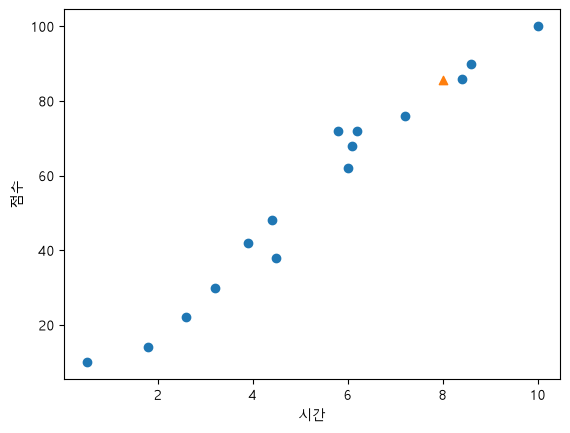

In [160]:
# 산점도 그래프
plt.scatter(train_data, train_label)
plt.scatter(8, 85.72, marker='^')
# plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
plt.xlabel('시간')
plt.ylabel('점수')
plt.show()